# Assignment 4: English to Spanish with a Transformer

You train an **encoder-decoder Transformer** (Topic 32) from scratch that translates English
sentences into Spanish, and submit it. We translate **hidden English sentences** with your
model and score the output with **BLEU** (higher is better). Details, the grade lines and the
tips are on the [assignment page](https://dongchul.kim/csci6379-fall2026/assignment/4).

This notebook runs the whole pipeline with a small starting point: a **part of the data**,
**short sentences**, and **one layer** each in the encoder and the decoder. It trains in a few
minutes and translates, badly. Everything in it is yours to improve.

| step | what happens |
|---|---|
| 0, 1 | check the GPU, install sacreBLEU; connect Google Drive for checkpoints |
| 2 | download the sentence pairs and look at them |
| 3 | **settings**: how much data, how long the sentences, how big the network, how long to train |
| 4 | `model.py`: the tokenizer, the Transformer and the decoding (**your file**) |
| 5 | `mt.py`: data, vocabularies, the training loop, BLEU |
| 6 | train (resumable) |
| 7 | BLEU on the dev set, and some translations |
| 8 | build, check and submit `submission.zip` |

> **Submit this starter once, early**, so that the whole path (notebook, zip, portal, score) is
> tested while there is time. Then improve and submit again.

## Step 0: GPU and packages

**Runtime > Change runtime type > T4 GPU** before running.

In [1]:
import os, sys, json, time, math, random, zipfile
import numpy as np
import torch
import matplotlib.pyplot as plt

!pip -q install sacrebleu==2.6.0
dev = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| device:", dev, torch.cuda.get_device_name(0) if dev == "cuda" else "")
if dev != "cuda":
    print("No GPU. Training works on a CPU but is much slower: Runtime > Change runtime type > T4 GPU.")

torch 2.11.0+cu128 | device: cuda NVIDIA GeForce RTX 5070


## Step 1: A folder for checkpoints

Colab sessions disconnect, often after an hour or two. The training loop saves a checkpoint
after every epoch and resumes from it, so connect Google Drive and nothing is lost. (If you
decline the Drive prompt, the checkpoint stays in the session and disappears with it.)

In [2]:
WORK_DIR = "."
try:
    from google.colab import drive
    drive.mount("/content/drive")
    WORK_DIR = "/content/drive/MyDrive/csci6379_hw4"
    os.makedirs(WORK_DIR, exist_ok=True)
    print("checkpoints go to", WORK_DIR)
except Exception as e:
    print("Drive not connected (" + type(e).__name__ + "); checkpoints stay in this session.")

Drive not connected (ModuleNotFoundError); checkpoints stay in this session.


## Step 2: The data

Two tab-separated files from the [Tatoeba](https://tatoeba.org) collection (CC-BY 2.0 FR, via
manythings.org), English first, Spanish second:

| file | pairs | use |
|---|---|---|
| `train.tsv` | about 140,000 | training (one English sentence may have several Spanish versions) |
| `dev.tsv` | 1,000 | measuring BLEU as you go; **not** in `train.tsv` |

The hidden sentences we grade with are of the same kind: everyday sentences, 3 to 12 words.
They are in neither file.

142476 training pairs, 1000 dev pairs
  'There were no side effects.'                 -> 'No hubo efectos secundarios.'
  "Don't spill the beans."                      -> 'No descubras el pastel.'
  'I am feeling wonderfully refreshed.'         -> 'Me siento maravillosamente refrescado.'
  'That experience left a bad taste in my mouth.' -> 'Esa experiencia me dejó un mal sabor de boca.'
  'I intend to do so.'                          -> 'Tengo la intención de hacerlo.'
  'Dogs are fun.'                               -> 'Los perros son divertidos.'


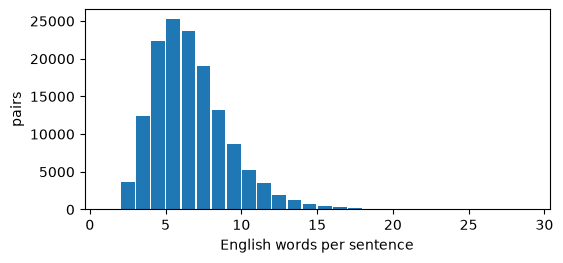

In [3]:
import urllib.request

DATA_BASE = "https://dlarena976f6f2c01.blob.core.windows.net/public/a4"
for name in ("train.tsv", "dev.tsv"):
    if not os.path.exists(name):
        urllib.request.urlretrieve(f"{DATA_BASE}/{name}", name)
        print("downloaded", name)

def read_tsv(path):
    import csv
    with open(path, encoding="utf-8", newline="") as f:
        return [(r[0], r[1]) for r in csv.reader(f, delimiter="\t", quoting=csv.QUOTE_NONE) if len(r) >= 2]

train_raw, dev_raw = read_tsv("train.tsv"), read_tsv("dev.tsv")
print(len(train_raw), "training pairs,", len(dev_raw), "dev pairs")
for e, s in random.Random(3).sample(train_raw, 6):
    print(f"  {e!r:45s} -> {s!r}")
lens = [len(e.split()) for e, _ in train_raw]
plt.figure(figsize=(6, 2.6)); plt.hist(lens, bins=range(1, 30), rwidth=0.9)
plt.xlabel("English words per sentence"); plt.ylabel("pairs"); plt.show()

## Step 3: Settings

This is where the starter is deliberately small. Each line is a knob (see the tips on the
assignment page for what each one buys):

| knob | starter | what it does |
|---|---|---|
| `N_PAIRS` | 20,000 | how many training pairs to use (there are about 140,000) |
| `MAX_LEN` | 10 | longest sentence, in tokens, on either side; longer pairs are dropped |
| `CONFIG` | d 128, 4 heads, **1 layer**, FF 256 | the Transformer's size |
| `EPOCHS` | 10 | how many passes over the data |
| `MIN_FREQ` | 1 | a word must appear this often to get its own id (else `<unk>`) |

In [4]:
N_PAIRS = 140_000           # of about 140,000
MAX_LEN = 20               # tokens per side (a word or a punctuation mark is one token)
MIN_FREQ = 1
CONFIG = dict(d=256, h=8, n_layers=3, d_ff=1024, max_len=MAX_LEN, dropout=0.1)
EPOCHS = 50
BATCH_SIZE = 64
LR = 1e-3
LABEL_SMOOTHING = 0.1
WARMUP = 1000                 # 0 = constant learning rate
CKPT = os.path.join(WORK_DIR, "ckpt.pt")   # delete this file to start training over

## Step 4: `model.py`, your file

The Topic 32 Transformer, with dropout, plus the two things the grader needs around it: the
tokenizer (lower-case words, punctuation split off) and a `Translator` class that is built from
`vocab.json`, trains through `forward(src, tgt_in)` and translates with greedy decoding, one
word at a time. **This file is submitted with your weights.** The contract at the top is the
only thing that must stay true; the network and the decoding are yours to change.

In [5]:
%%writefile model.py
# model.py: your English -> Spanish translator for CSCI 6379 Assignment 4.
#
# WHAT I BASED THIS DESIGN ON (required, keep this up to date):
#   The Topic 32 Transformer from the course (one attention class, encoder and decoder
#   layers, greedy decoding), unchanged except for dropout.
#   (Replace this with your own words: the papers, tutorials or course notes you used,
#    and what you changed. One to five lines is enough.)
#
# The contract with the grader (the only things that must stay true):
#   * This file defines class Translator(torch.nn.Module). The grader runs it in a folder
#     holding exactly model.py, vocab.json and weights.pt, builds it as Translator() with no
#     arguments (so everything it needs comes from vocab.json), loads weights.pt into it with
#     strict=True, moves it to the GPU, and calls
#         translator.translate(sentences)     # a list of English strings
#     which must return a list of Spanish strings, one per input, in the same order.
#   * At most 30,000,000 parameters, trained from scratch on the provided data only.
#   * Only torch, numpy and the Python standard library are available in the grader
#     (plus the `tokenizers` and `sentencepiece` packages, if you want subword units).
#     Do not import other files of your own.
#
# Everything else is yours: the tokenizer, the vocabularies, the network, the decoding.
import json
import math
import re
import unicodedata

import torch
import torch.nn as nn
from torch.nn.utils.rnn import pad_sequence

PAD, SOS, EOS, UNK = 0, 1, 2, 3      # the four special token ids, as in Topic 32


# ---------------------------------------------------------------- tokens and vocabularies
_TOKEN = re.compile(r"\w+|[^\w\s]")  # words, and each punctuation mark on its own


def tokenize(text):
    """'Where's Tom?' -> ['where', "'", 's', 'tom', '?']   (lower-cased; accents are kept)"""
    return _TOKEN.findall(unicodedata.normalize("NFC", text).lower())


def detokenize(tokens):
    """['¿', 'dónde', 'está', 'tom', '?'] -> '¿dónde está tom?'"""
    out = ""
    for t in tokens:
        if out and t not in ".,;:!?)" and not out.endswith(("¿", "¡", "(")):
            out += " "
        out += t
    return out


class Vocab:
    """itos: the list of tokens, index = id. The first four are <pad>, <sos>, <eos>, <unk>."""

    def __init__(self, itos):
        self.itos = list(itos)
        self.stoi = {w: i for i, w in enumerate(self.itos)}

    @classmethod
    def build(cls, token_lists, min_freq=1):
        counts = {}
        for toks in token_lists:
            for w in toks:
                counts[w] = counts.get(w, 0) + 1
        words = sorted(w for w, c in counts.items() if c >= min_freq)
        return cls(["<pad>", "<sos>", "<eos>", "<unk>"] + words)

    def encode(self, tokens):                     # tokens -> [<sos>, ids..., <eos>]
        return [SOS] + [self.stoi.get(w, UNK) for w in tokens] + [EOS]

    def decode(self, ids):                        # ids -> tokens, stopping at <eos>
        out = []
        for i in ids:
            if i == EOS:
                break
            if i not in (PAD, SOS):
                out.append(self.itos[i])
        return out

    def __len__(self):
        return len(self.itos)


# ---------------------------------------------------------------- the Transformer (Topic 32)
class MultiHeadAttention(nn.Module):
    def __init__(self, d, h):
        super().__init__()
        self.h, self.dk = h, d // h
        self.q, self.k = nn.Linear(d, d), nn.Linear(d, d)
        self.v, self.o = nn.Linear(d, d), nn.Linear(d, d)

    def forward(self, x_q, x_kv, mask):           # mask: True = may look
        B, Tq, d = x_q.shape

        def split(t):                             # (B,T,d) -> (B,h,T,dk)
            return t.view(B, -1, self.h, self.dk).transpose(1, 2)
        Q = split(self.q(x_q))
        K, V = split(self.k(x_kv)), split(self.v(x_kv))
        scores = Q @ K.transpose(-2, -1) / math.sqrt(self.dk)
        scores = scores.masked_fill(~mask, float("-inf"))
        out = torch.softmax(scores, dim=-1) @ V
        out = out.transpose(1, 2).reshape(B, Tq, d)
        return self.o(out)


def pad_mask(src):                                # (B, 1, 1, Ts): nobody looks at <pad>
    return (src != PAD)[:, None, None, :]


def causal_mask(tgt):                             # (B, 1, Tt, Tt): position t sees <= t, not <pad>
    T = tgt.size(1)
    past = torch.ones(T, T, dtype=torch.bool, device=tgt.device).tril()
    return past & (tgt != PAD)[:, None, None, :]


def feed_forward(d, d_ff, dropout):
    return nn.Sequential(nn.Linear(d, d_ff), nn.ReLU(), nn.Dropout(dropout), nn.Linear(d_ff, d))


class EncoderLayer(nn.Module):
    def __init__(self, d, h, d_ff, dropout):
        super().__init__()
        self.attn = MultiHeadAttention(d, h)
        self.ff = feed_forward(d, d_ff, dropout)
        self.norm1, self.norm2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.drop = nn.Dropout(dropout)

    def forward(self, x, src_mask):
        x = self.norm1(x + self.drop(self.attn(x, x, src_mask)))
        return self.norm2(x + self.drop(self.ff(x)))


class DecoderLayer(nn.Module):
    def __init__(self, d, h, d_ff, dropout):
        super().__init__()
        self.self_attn = MultiHeadAttention(d, h)
        self.cross = MultiHeadAttention(d, h)
        self.ff = feed_forward(d, d_ff, dropout)
        self.norm1, self.norm2, self.norm3 = (nn.LayerNorm(d) for _ in range(3))
        self.drop = nn.Dropout(dropout)

    def forward(self, y, memory, tgt_mask, src_mask):
        y = self.norm1(y + self.drop(self.self_attn(y, y, tgt_mask)))
        y = self.norm2(y + self.drop(self.cross(y, memory, src_mask)))
        return self.norm3(y + self.drop(self.ff(y)))


class Transformer(nn.Module):
    """max_len: the most tokens a sentence may have (without <sos>/<eos>)."""

    def __init__(self, src_vocab, tgt_vocab, d=128, h=4, n_layers=1, d_ff=256, max_len=10, dropout=0.1):
        super().__init__()
        self.d, self.max_len = d, max_len
        self.src_emb = nn.Embedding(src_vocab, d)
        self.tgt_emb = nn.Embedding(tgt_vocab, d)
        self.pos = nn.Embedding(max_len + 2, d)   # + <sos> and <eos>
        self.drop = nn.Dropout(dropout)
        self.enc = nn.ModuleList(EncoderLayer(d, h, d_ff, dropout) for _ in range(n_layers))
        self.dec = nn.ModuleList(DecoderLayer(d, h, d_ff, dropout) for _ in range(n_layers))
        self.out = nn.Linear(d, tgt_vocab)

    def embed(self, emb, ids):
        pos = torch.arange(ids.size(1), device=ids.device)
        return self.drop(emb(ids) + self.pos(pos))

    def encode(self, src):
        x = self.embed(self.src_emb, src)
        for layer in self.enc:
            x = layer(x, pad_mask(src))
        return x                                  # memory

    def decode(self, tgt, memory, src):
        y = self.embed(self.tgt_emb, tgt)
        for layer in self.dec:
            y = layer(y, memory, causal_mask(tgt), pad_mask(src))
        return self.out(y)                        # (B, Tt, tgt_vocab) logits

    def forward(self, src, tgt_in):
        return self.decode(tgt_in, self.encode(src), src)


# ---------------------------------------------------------------- what the grader uses
class Translator(nn.Module):
    """Built from vocab.json alone: {"en": [...], "es": [...], "cfg": {...}}."""

    def __init__(self, vocab_file="vocab.json"):
        super().__init__()
        with open(vocab_file, encoding="utf-8") as f:
            v = json.load(f)
        self.en, self.es, self.cfg = Vocab(v["en"]), Vocab(v["es"]), dict(v["cfg"])
        self.net = Transformer(len(self.en), len(self.es), **self.cfg)

    def forward(self, src, tgt_in):               # training: logits for the whole target at once
        return self.net(src, tgt_in)

    def encode_src(self, sentences, device):
        L = self.cfg["max_len"]
        ids = [torch.tensor(self.en.encode(tokenize(s)[:L])) for s in sentences]
        return pad_sequence(ids, batch_first=True).to(device)

    @torch.no_grad()
    def translate(self, sentences, batch_size=64):
        """English strings -> Spanish strings, greedy, one word at a time (Topic 32, batched)."""
        self.eval()
        device = next(self.parameters()).device
        L = self.cfg["max_len"]
        out = []
        for b in range(0, len(sentences), batch_size):
            src = self.encode_src(sentences[b:b + batch_size], device)
            memory = self.net.encode(src)
            ys = torch.full((src.size(0), 1), SOS, dtype=torch.long, device=device)
            done = torch.zeros(src.size(0), dtype=torch.bool, device=device)
            for _ in range(L + 1):
                nxt = self.net.decode(ys, memory, src)[:, -1].argmax(-1)
                nxt[done] = PAD
                ys = torch.cat([ys, nxt[:, None]], 1)
                done |= nxt == EOS
                if bool(done.all()):
                    break
            out += [detokenize(self.es.decode(row.tolist())) for row in ys]
        return out

Overwriting model.py


## Step 5: `mt.py`, training utilities

Reading the files, tokenising, building the vocabularies, minibatches with teacher forcing,
the training loop (checkpoint after every epoch, resume), and BLEU exactly as the grader
computes it (sacreBLEU, case-insensitive).

In [6]:
%%writefile mt.py
# mt.py: data, vocabularies, the training loop and BLEU for Assignment 4. You may edit it.
import csv
import json
import math
import os
import random
import time

import torch
import torch.nn as nn
from torch.nn.utils.rnn import pad_sequence

from model import PAD, Vocab, tokenize

csv.field_size_limit(1 << 24)


def read_tsv(path):
    """[(english, spanish), ...] from a tab-separated file (extra columns are ignored)."""
    with open(path, encoding="utf-8", newline="") as f:
        return [(r[0], r[1]) for r in csv.reader(f, delimiter="\t", quoting=csv.QUOTE_NONE) if len(r) >= 2]


def load_pairs(path, n_pairs=None, max_len=None, seed=0):
    """Tokenised pairs: shuffled with `seed`, both sides at most max_len tokens, the first n_pairs."""
    pairs = [(tokenize(e), tokenize(s)) for e, s in read_tsv(path)]
    if max_len:
        pairs = [(e, s) for e, s in pairs if len(e) <= max_len and len(s) <= max_len]
    random.Random(seed).shuffle(pairs)
    return pairs[:n_pairs] if n_pairs else pairs


def build_vocabs(pairs, min_freq=1):
    return Vocab.build((e for e, _ in pairs), min_freq), Vocab.build((s for _, s in pairs), min_freq)


def write_vocab(path, en, es, cfg):
    with open(path, "w", encoding="utf-8") as f:
        json.dump({"en": en.itos, "es": es.itos, "cfg": cfg}, f, ensure_ascii=False)


def batches(pairs, en, es, batch_size, seed):
    """Shuffled minibatches of (src, tgt_in, tgt_out), padded with 0."""
    order = list(range(len(pairs)))
    random.Random(seed).shuffle(order)
    for b in range(0, len(order), batch_size):
        chunk = [pairs[i] for i in order[b:b + batch_size]]
        src = pad_sequence([torch.tensor(en.encode(e)) for e, _ in chunk], batch_first=True)
        tgt = pad_sequence([torch.tensor(es.encode(s)) for _, s in chunk], batch_first=True)
        yield src, tgt[:, :-1], tgt[:, 1:]


def n_params(model):
    return sum(p.numel() for p in model.parameters())


def train(model, pairs, epochs, ckpt=None, batch_size=64, lr=1e-3, label_smoothing=0.0,
          warmup=0, log=print):
    """Teacher forcing, cross-entropy that skips <pad>. Resumes from `ckpt` if it exists and
    saves there after every epoch, so a Colab disconnect costs at most one epoch. Returns
    the list of per-epoch mean losses."""
    device = next(model.parameters()).device
    opt = torch.optim.Adam(model.parameters(), lr=lr, betas=(0.9, 0.98))
    loss_fn = nn.CrossEntropyLoss(ignore_index=PAD, label_smoothing=label_smoothing)
    start, losses, step = 1, [], 0
    if ckpt and os.path.exists(ckpt):
        state = torch.load(ckpt, map_location=device, weights_only=True)
        model.load_state_dict(state["model"]); opt.load_state_dict(state["opt"])
        start, losses, step = state["epoch"] + 1, state["losses"], state.get("step", 0)
        log(f"resumed from {ckpt}: {state['epoch']} epochs done")
    steps_per_epoch = math.ceil(len(pairs) / batch_size)
    for epoch in range(start, epochs + 1):
        model.train(); t0 = time.time(); total = 0.0; count = 0
        for src, tgt_in, tgt_out in batches(pairs, model.en, model.es, batch_size, seed=epoch):
            src, tgt_in, tgt_out = src.to(device), tgt_in.to(device), tgt_out.to(device)
            if warmup:                                        # linear warm-up, then 1/sqrt(step) decay
                step += 1
                for g in opt.param_groups:
                    g["lr"] = lr * min(step / warmup, math.sqrt(warmup / step))
            logits = model(src, tgt_in)
            loss = loss_fn(logits.flatten(0, 1), tgt_out.flatten())
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            total += loss.item() * len(src); count += len(src)
        losses.append(total / count)
        log(f"epoch {epoch:3d}/{epochs}  loss {losses[-1]:.4f}  ({time.time() - t0:.0f} s, "
            f"{steps_per_epoch} steps)")
        if ckpt:
            torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "epoch": epoch,
                        "losses": losses, "step": step}, ckpt + ".tmp")
            os.replace(ckpt + ".tmp", ckpt)
    return losses


def bleu(hypotheses, references):
    """Corpus BLEU as the grader computes it: sacreBLEU, international tokenisation (so that
    '¿' and '¡' count as tokens of their own), case-insensitive, one reference per sentence.
    0 to 100, higher is better."""
    import sacrebleu
    return sacrebleu.corpus_bleu(hypotheses, [references], lowercase=True, tokenize="intl", force=True).score


def evaluate(model, dev_pairs, batch_size=64):
    """BLEU of model.translate on raw (english, spanish) pairs."""
    hyps = model.translate([e for e, _ in dev_pairs], batch_size=batch_size)
    return bleu(hyps, [s for _, s in dev_pairs]), hyps

Overwriting mt.py


## Step 6: Build the vocabularies and train

`vocab.json` records the two vocabularies **and `CONFIG`**: `Translator()` rebuilds your network
from it, in the notebook and in the grader. Build it once per training run; if you change
`CONFIG`, `N_PAIRS`, `MAX_LEN` or `MIN_FREQ`, delete the checkpoint and build it again.

In [7]:
import importlib, model, mt
importlib.reload(model); importlib.reload(mt)

pairs = mt.load_pairs("train.tsv", n_pairs=N_PAIRS, max_len=MAX_LEN, seed=0)
en, es = mt.build_vocabs(pairs, min_freq=MIN_FREQ)
mt.write_vocab("vocab.json", en, es, CONFIG)
print(f"{len(pairs):,} pairs of at most {MAX_LEN} tokens; vocabularies: {len(en):,} English, {len(es):,} Spanish")

translator = model.Translator("vocab.json").to(dev)
print(f"{mt.n_params(translator):,} parameters (limit 30,000,000)")

140,000 pairs of at most 20 tokens; vocabularies: 13,865 English, 27,930 Spanish
23,412,762 parameters (limit 30,000,000)


resumed from .\ckpt.pt: 36 epochs done
epoch  37/50  loss 2.0882  (64 s, 2188 steps)
epoch  38/50  loss 2.0845  (45 s, 2188 steps)
epoch  39/50  loss 2.0799  (45 s, 2188 steps)
epoch  40/50  loss 2.0768  (48 s, 2188 steps)
epoch  41/50  loss 2.0724  (49 s, 2188 steps)
epoch  42/50  loss 2.0703  (47 s, 2188 steps)
epoch  43/50  loss 2.0675  (46 s, 2188 steps)
epoch  44/50  loss 2.0629  (45 s, 2188 steps)
epoch  45/50  loss 2.0594  (45 s, 2188 steps)
epoch  46/50  loss 2.0564  (45 s, 2188 steps)
epoch  47/50  loss 2.0531  (45 s, 2188 steps)
epoch  48/50  loss 2.0490  (45 s, 2188 steps)
epoch  49/50  loss 2.0462  (45 s, 2188 steps)
epoch  50/50  loss 2.0427  (45 s, 2188 steps)


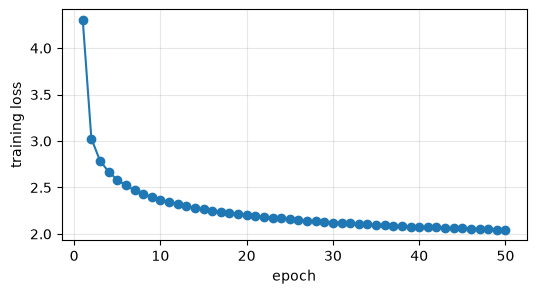

In [8]:
losses = mt.train(translator, pairs, EPOCHS, ckpt=CKPT, batch_size=BATCH_SIZE, lr=LR,
                  label_smoothing=LABEL_SMOOTHING, warmup=WARMUP)
plt.figure(figsize=(6, 3)); plt.plot(range(1, len(losses) + 1), losses, marker="o")
plt.xlabel("epoch"); plt.ylabel("training loss"); plt.grid(alpha=0.3); plt.show()

**Check:** the loss falls every epoch. If it is still falling steeply at the end, more epochs
will help (raise `EPOCHS` and run the cell again: it resumes from the checkpoint).

## Step 7: BLEU on the dev set

`dev.tsv` is not in your training data, so this is an honest estimate of your hidden score
(the hidden sentences are of the same kind, so expect a similar number).

In [9]:
score, hyps = mt.evaluate(translator, dev_raw)
print(f"dev BLEU {score:.1f}")
for (e, s), h in list(zip(dev_raw, hyps))[:12]:
    print(f"  {e!r:45s} -> {h!r:45s}  (reference: {s!r})")

dev BLEU 50.2
  "That's quite absurd."                        -> 'eso es bastante absurdo.'                     (reference: 'Eso es completamente absurdo.')
  "It isn't a dream."                           -> 'no es un sueño.'                              (reference: 'Esto no es un sueño.')
  "Come here. I'll help you."                   -> 'ven acá. te ayudaré.'                         (reference: '¡Ven! Yo te ayudo.')
  'We are his sons.'                            -> 'somos sus hijos.'                             (reference: 'Nosotros somos sus hijos.')
  'Tom overheard Mary talking about him.'       -> 'tom hizo que mary habla de él.'               (reference: 'Tom oyó por casualidad a Mary hablar acerca de él.')
  'We used to go to the movies on Saturday evening.' -> 'solíamos ir al cine los sábados de la noche.'  (reference: 'Los sábados por la tarde solíamos ir al cine.')
  "I don't know."                               -> 'no lo sé.'                                    (reference:

In [10]:
for s in ["Where is the station?", "Tom is my best friend.", "I don't like cold weather.",
          "Can you help me with my homework?", "We will leave early tomorrow morning."]:
    print(f"  {s!r:45s} -> {translator.translate([s])[0]!r}")

  'Where is the station?'                       -> '¿dónde está la estación?'
  'Tom is my best friend.'                      -> 'tom es mi mejor amigo.'
  "I don't like cold weather."                  -> 'no me gusta el tiempo frío.'
  'Can you help me with my homework?'           -> '¿me ayudas con los deberes?'
  'We will leave early tomorrow morning.'       -> 'nos iremos temprano mañana por la mañana.'


**What to expect:** the starter scores low: it has seen a seventh of the data, nothing longer
than 10 tokens, and has one layer. Long or unfamiliar sentences come out short, repeated or
with `<unk>`. The [assignment page](https://dongchul.kim/csci6379-fall2026/assignment/4) lists what to change, roughly in order of payoff.

## Step 8: Build, check and submit

`submission.zip` holds three files:

| file | what it is |
|---|---|
| `model.py` | your file from Step 4 |
| `vocab.json` | the vocabularies and `CONFIG` your network was trained with |
| `weights.pt` | the trained weights, a plain `state_dict` |

The checker runs the same checks as the portal, in a fresh Python process that sees only the
three files: `Translator` imports from `model.py` alone, `Translator()` has at most 30,000,000
parameters, `weights.pt` loads with `strict=True`, and `translate()` returns one string per
sentence on the CPU and the GPU. It checks the form of your submission, not how good it is.

In [11]:
%%writefile check_submission.py
# check_submission.py: checks submission.zip the way the portal does. DO NOT EDIT.
#     python check_submission.py submission.zip
# It unpacks the zip into an empty folder and, in a fresh Python process that can only see
# that folder, imports model.py, builds Translator(), loads weights.pt and translates.
import os, subprocess, sys, tempfile, zipfile

MAX_PARAMS = 30_000_000
REQUIRED = ["model.py", "vocab.json", "weights.pt"]

CHILD = """
import os, sys, time
import torch
failed = []
def ok(msg): print("  ok    " + msg, flush=True)
def bad(msg): print("  FAIL  " + msg, flush=True); failed.append(msg)
try:
    from model import Translator                     # only the three files are in this folder
    import model
    assert os.path.dirname(os.path.abspath(model.__file__)) == os.getcwd(), model.__file__
    ok("model.py imports on its own and defines Translator")
except Exception as e:
    bad(f"importing Translator from model.py alone failed: {type(e).__name__}: {e}"); sys.exit(1)
try:
    tr = Translator()
except Exception as e:
    bad(f"Translator() with no arguments failed: {type(e).__name__}: {e}"); sys.exit(1)
n = sum(p.numel() for p in torch.nn.Module.parameters(tr))
(ok if n <= %d else bad)(f"{n:,} parameters (limit %s)")
try:
    sd = torch.load("weights.pt", map_location="cpu", weights_only=True)
    tr.load_state_dict(sd, strict=True)
    ok(f"weights.pt loads into a fresh Translator with strict=True ({os.path.getsize('weights.pt') / 1e6:.1f} MB)")
except Exception as e:
    bad(f"weights.pt does not load into Translator() with strict=True: {type(e).__name__}: {e}"); sys.exit(1)
tr.eval()
sents = ["Where is the station?", "Tom is my best friend.", "I don't like cold weather.",
         "Can you help me with my homework?", "We will leave early tomorrow morning."]
def check_out(out, where):
    if not isinstance(out, list) or len(out) != len(sents) or not all(isinstance(s, str) for s in out):
        bad(f"{where}: translate() must return a list of {len(sents)} strings; got "
            f"{type(out).__name__} of length {len(out) if hasattr(out, '__len__') else '?'}"); return False
    ok(f"{where}: {len(out)} sentences in, {len(out)} strings out"); return True
try:
    out = tr.translate(sents)
except Exception as e:
    bad(f"translate() failed on the CPU: {type(e).__name__}: {e}"); sys.exit(1)
if check_out(out, "CPU"):
    for e, s in zip(sents[:3], out[:3]): print(f"          {e!r} -> {s!r}")
if torch.cuda.is_available():
    try:
        tr = tr.cuda()
        t0 = time.time(); outg = tr.translate(sents); dt = time.time() - t0
    except Exception as e:
        bad(f"translate() failed on the GPU: {type(e).__name__}: {e}"); sys.exit(1)
    if check_out(outg, "GPU"):
        t0 = time.time(); tr.translate(sents * 20); per100 = time.time() - t0
        ok(f"100 sentences take {per100:.1f} s on this GPU ({torch.cuda.get_device_name(0)}); "
           f"the grader translates about 1,000, so roughly {per100 * 10:.0f} s there (limit 15 min)")
else:
    print("  note  no GPU in this session: skipped the GPU translation and the timing")
sys.exit(1 if failed else 0)
""" % (MAX_PARAMS, f"{MAX_PARAMS:,}")


def main(zpath):
    if not os.path.exists(zpath):
        print(f"FAILED: {zpath} not found"); return 1
    with zipfile.ZipFile(zpath) as z:
        names = sorted(z.namelist())
        if names != REQUIRED:
            print(f"FAILED: the zip must hold exactly {', '.join(REQUIRED)}, at the top level. It holds {names}")
            return 1
        tmp = tempfile.mkdtemp(prefix="hw4check_")
        z.extractall(tmp)
    sizes = {n: os.path.getsize(os.path.join(tmp, n)) for n in REQUIRED}
    print(f"checking {zpath} (model.py {sizes['model.py']:,} bytes, vocab.json {sizes['vocab.json'] / 1e6:.2f} MB, "
          f"weights.pt {sizes['weights.pt'] / 1e6:.1f} MB)", flush=True)
    if sizes["model.py"] > 256 * 1024 or sizes["vocab.json"] > 8 * 1024 * 1024 or sizes["weights.pt"] > 160 * 1024 * 1024:
        print("FAILED: limits are model.py 256 KB, vocab.json 8 MB, weights.pt 160 MB"); return 1
    r = subprocess.run([sys.executable, "-c", CHILD], cwd=tmp)
    print("PASSED" if r.returncode == 0 else "FAILED: fix the lines marked FAIL above, rebuild the zip, check again")
    return r.returncode


if __name__ == "__main__":
    sys.exit(main(sys.argv[1] if len(sys.argv) > 1 else "submission.zip"))

Overwriting check_submission.py


In [12]:
torch.save({k: v.detach().cpu() for k, v in translator.state_dict().items()}, "weights.pt")
with zipfile.ZipFile("submission.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for name in ("model.py", "vocab.json", "weights.pt"):
        z.write(name)
print(f"built submission.zip ({os.path.getsize('submission.zip') / 1e6:.1f} MB)")
!{sys.executable} check_submission.py submission.zip

built submission.zip (86.9 MB)
checking submission.zip (model.py 9,293 bytes, vocab.json 0.49 MB, weights.pt 93.7 MB)
  ok    model.py imports on its own and defines Translator
  ok    23,412,762 parameters (limit 30,000,000)
  ok    weights.pt loads into a fresh Translator with strict=True (93.7 MB)
  ok    CPU: 5 sentences in, 5 strings out
          'Where is the station?' -> '¿dónde está la estación?'
          'Tom is my best friend.' -> 'tom es mi mejor amigo.'
          "I don't like cold weather." -> 'no me gusta el tiempo frío.'
  ok    GPU: 5 sentences in, 5 strings out
  ok    100 sentences take 0.3 s on this GPU (NVIDIA GeForce RTX 5070); the grader translates about 1,000, so roughly 3 s there (limit 15 min)
PASSED


**Check:** the last line reads `PASSED`. If it says `FAILED`, each `FAIL` line says what is wrong.

In [13]:
# Download submission.zip (files in the session disappear when Colab disconnects).
try:
    from google.colab import files
    files.download("submission.zip")
except Exception:                                # not running in Colab
    print("submission.zip is at", os.path.abspath("submission.zip"))

submission.zip is at c:\Users\serna\Documents\2026\Language_Translator\submission.zip


**Submit.** Sign in to the [portal's /hw4 page](https://dlarena-r2-web.azurewebsites.net/hw4) with your Assignment 1 account and
upload `submission.zip`.

- We translate about **1,000 hidden English sentences** with your `Translator` and compute BLEU
  against their Spanish references. The score appears on the [board](https://dongchul.kim/csci6379-fall2026/leaderboard/assignment4) a few minutes after
  you upload, with your model's translations of a few sample sentences.
- Up to **3 submissions per day**. **Your grade uses the score of your last submission before the
  deadline** (on the assignment page).

Then make it better: more data, longer sentences, more layers, a wider model, more epochs,
and so on. The tips on the [assignment page](https://dongchul.kim/csci6379-fall2026/assignment/4) say what each one gained in our own runs.